In [63]:
import numpy as np

def extract_data( file, min_arrival, max_arrival ):
    X = []
    Y = []
    with open( file, "r") as file1:
        for line in file1.readlines():
            f_list = [float(i) for i in line.split(" ")]
            #print(f_list)
            found_one = True
            for p in f_list:
                if p > 0.00001:
                    found_one = True
            for p in f_list[:-1]:
                if p > 1:
                    found_one = False
            if( found_one and f_list[-1] < max_arrival and f_list[-1] > min_arrival ):#and ( f_list[-1] > 0.001 )):
                X.append( [f_list[i]+0.01 for i in range(0, len(f_list)-2)] )
                Y.append( f_list[-2] )
    return [X,Y]

In [104]:
[X, Y] = extract_data("exp_05_fanins_with_arrival.txt", 200, 10000 )

In [105]:
len(X)

1939

In [106]:
threshold = round(len(X) * 0.8 )

X_train = np.array([X[i] for i in range( threshold ) ])
Y_train = np.array([Y[i] for i in range( threshold ) ])
X_test = np.array([X[i] for i in range( threshold, len(X) ) ])
Y_test = np.array([Y[i] for i in range( threshold, len(Y) ) ])

In [107]:
from sklearn.linear_model import LinearRegression
reg = LinearRegression().fit(X_train, Y_train)

print(reg.score(X_train, Y_train))
print(reg.score(X_test, Y_test))

0.35988823262410863
0.14392675847633918


In [108]:
P_test = reg.predict(X_test)

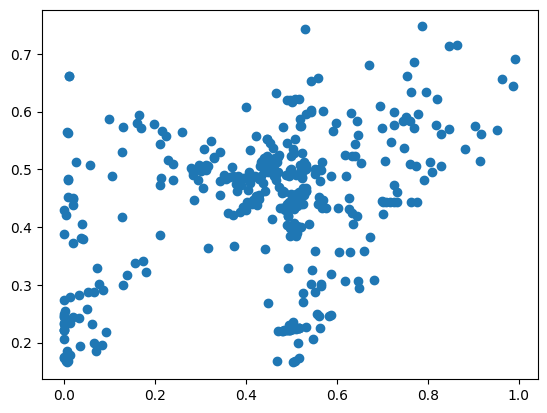

In [109]:
import matplotlib.pyplot as plt
plt.scatter( Y_test, P_test )

In [110]:
from sklearn.neural_network import MLPRegressor
#from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
#X, Y = make_regression(n_samples=threshold, random_state=1)
#X_train, X_test, y_train, y_test = train_test_split(X, Y,
                                                    #random_state=1)
regr = MLPRegressor( hidden_layer_sizes = (5,), random_state=1, max_iter=100).fit(X_train, Y_train)


print(regr.score(X_train, Y_train))
print(regr.score(X_test, Y_test))


0.33876921731140885
0.1400061924391076


In [102]:
len(X_train)

1941

In [103]:
len(Y_test)

485